# Phase 4 — Feature engineering et pipeline

**Objectif :** transformer les données nettoyées en entrées exploitables par un modèle, en traduisant les insights de l'EDA en variables, **sans aucune fuite de données**.

**Plan**
1. Découpage train/test (avant toute transformation)
2. Features métier
3. Prétraitement et pipeline scikit-learn
4. Validation des choix par validation croisée

> **Règle d'or :** le jeu de test est mis sous clé dès la section 1. Toutes les décisions de ce notebook sont prises **uniquement sur le jeu d'entraînement**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from churn.config import TARGET, RANDOM_STATE
from churn.data import load_clean
from churn.features import split_data
from churn.viz import set_style, save_fig, fmt_pct, fmt_int, BLUE, ORANGE, TEXT, TEXT_SECONDARY, GRID

set_style()
df = load_clean()

## 1. Découpage train/test stratifié

- **80 % entraînement / 20 % test**, avec un découpage **stratifié** (même proportion de churners dans chaque jeu).
- Le découpage est fait **avant** toute transformation : si on standardisait les données avant de découper, la moyenne et l'écart-type incluraient les clients de test, et l'évaluation serait biaisée (*data leakage*).

In [2]:
X_train, X_test, y_train, y_test = split_data(df)

summary = pd.DataFrame({
    "clients": [len(X_train), len(X_test), len(df)],
    "churners": [y_train.sum(), y_test.sum(), df[TARGET].sum()],
    "taux_churn": [y_train.mean(), y_test.mean(), df[TARGET].mean()],
}, index=["Entraînement", "Test", "Total"])
summary.style.format({"taux_churn": "{:.2%}"})

,clients,churners,taux_churn
Entraînement,5634,1495,26.54%
Test,1409,374,26.54%
Total,7043,1869,26.54%


**Constat :** 5 634 clients d'entraînement et 1 409 de test, avec un taux de churn identique (~26,5 %) dans les deux jeux. Le jeu de test n'est **plus utilisé avant la Phase 6**.

## 2. Features métier

Cinq features **candidates** traduisent les insights de la Phase 3. Elles seront toutes testées ; seules celles qui améliorent réellement un modèle seront gardées (section 4).

| Feature | Calcul | Insight d'origine |
|---|---|---|
| `nb_protections` | nombre de services de protection (0–4) | Effet dose des services de protection |
| `nb_streaming` | nombre de services de streaming (0–2) | Niveau d'engagement |
| `is_new_client` | ancienneté ≤ 6 mois | Les 6 premiers mois sont critiques |
| `log_tenure` | log(1 + ancienneté) | Le risque chute vite au début puis se stabilise (relation non linéaire) |
| `fiber_month_to_month` | fibre **et** contrat mensuel | Segment prioritaire (interaction qu'un modèle linéaire ne crée pas seul) |

Variables retirées : `gender` et `PhoneService` (aucun lien avec le churn), `TotalCharges` (≈ ancienneté × facture mensuelle).

Le tout est encapsulé dans `ChurnFeatureEngineer`, un transformateur scikit-learn **sans état** : il n'apprend rien des données, donc il ne peut pas provoquer de fuite.

In [3]:
from churn.config import CANDIDATE_FEATURES, SELECTED_FEATURES
from churn.features import ChurnFeatureEngineer

engineer = ChurnFeatureEngineer(features=tuple(CANDIDATE_FEATURES))
X_train_fe = engineer.fit_transform(X_train)
new_cols = ["tenure", "log_tenure", "nb_protections", "nb_streaming", "is_new_client", "fiber_month_to_month"]
print(f"{X_train.shape[1]} variables en entrée → {X_train_fe.shape[1]} après feature engineering")
X_train_fe[new_cols].head()

19 variables en entrée → 21 après feature engineering


,tenure,log_tenure,nb_protections,nb_streaming,is_new_client,fiber_month_to_month
customerID,,,,,,
4950-BDEUX,35,3.583519,1,2,0,0
7993-NQLJE,15,2.772589,1,0,0,1
7321-ZNSLA,13,2.639057,3,0,0,0
4922-CVPDX,26,3.295837,2,2,0,0
2903-YYTBW,1,0.693147,0,0,1,0


**`log_tenure` est-il utile ?** Le taux de churn chute très vite les premiers mois puis décroît plus lentement. L'intuition est qu'un logarithme « redresse » cette courbe pour un modèle linéaire. Vérifions-le plutôt que de le supposer, avec des **déciles** (10 tranches d'effectifs égaux).

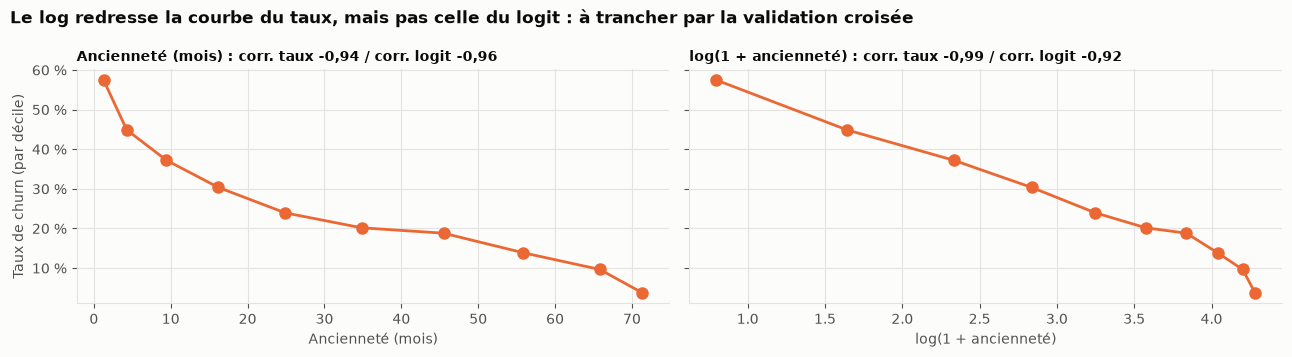

In [4]:
from scipy.special import logit

train_fe = X_train_fe.assign(churn=y_train)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
for ax, col, label in [(axes[0], "tenure", "Ancienneté (mois)"), (axes[1], "log_tenure", "log(1 + ancienneté)")]:
    deciles = train_fe.groupby(pd.qcut(train_fe[col], 10, duplicates="drop"), observed=True)
    stats_ = deciles.agg(x=(col, "mean"), rate=("churn", "mean"))
    corr_rate = np.corrcoef(stats_["x"], stats_["rate"])[0, 1]
    corr_logit = np.corrcoef(stats_["x"], logit(stats_["rate"]))[0, 1]
    ax.plot(stats_["x"], stats_["rate"], marker="o", markersize=8, lw=2, color=ORANGE)
    ax.set_xlabel(label)
    ax.yaxis.set_major_formatter(lambda v, _: fmt_pct(v, 0))
    fmt = lambda v: f"{v:+.2f}".replace(".", ",")
    ax.set_title(f"{label} : corr. taux {fmt(corr_rate)} / corr. logit {fmt(corr_logit)}", fontsize=10)
axes[0].set_ylabel("Taux de churn (par décile)")
fig.suptitle("Le log redresse la courbe du taux, mais pas celle du logit : à trancher par la validation croisée",
             x=0.01, ha="left", fontweight="bold", color=TEXT)
fig.tight_layout()
save_fig(fig, "04_log_tenure.png")
plt.show()

**Lecture (résultat nuancé) :**
- Sur l'échelle du **taux de churn**, `log_tenure` est plus linéaire (corrélation −0,99 contre −0,94).
- Mais une régression logistique est linéaire sur l'échelle du **logit** (log-odds), et là c'est l'**ancienneté brute** qui est la plus linéaire (−0,96 contre −0,92).

**Décision :** on garde **les deux** variables, et c'est la validation croisée (section 4) qui dira si `log_tenure` apporte quelque chose. Une intuition, même raisonnable, doit être **vérifiée par les chiffres**.

## 3. Prétraitement et pipeline scikit-learn

| Étape | Variables | Transformation | Pourquoi |
|---|---|---|---|
| Features métier | toutes | `ChurnFeatureEngineer` | Ajout des 5 features, retrait des 3 variables inutiles |
| Encodage | catégorielles | `OneHotEncoder(drop="if_binary", handle_unknown="ignore")` | Les modèles n'acceptent que des nombres ; une modalité inconnue ne fait pas planter l'app |
| Mise à l'échelle | numériques | `StandardScaler` | Moyenne 0, écart-type 1 : aucune variable n'écrase les autres (crucial pour la régression logistique) |

Les trois étapes et le modèle forment **un seul objet `Pipeline`**. En validation croisée, chaque étape est réajustée **uniquement sur les plis d'entraînement**, ce qui empêche toute fuite, et l'application n'aura qu'un seul objet à charger.

In [5]:
from sklearn.linear_model import LogisticRegression
from churn.features import build_pipeline

pipe = build_pipeline(LogisticRegression(max_iter=1000))
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('preprocess', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,features,"('log_tenure', ...)"
,drop_cols,"('gender', ...)"
,merge_no_internet,True
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatt

In [6]:
pipe.fit(X_train, y_train)
X_train_ready = pipe[:-1].transform(X_train)   # tout le pipeline sauf le modèle
print(f"Matrice prête pour le modèle : {X_train_ready.shape[0]} clients × {X_train_ready.shape[1]} colonnes")
print("Valeurs manquantes :", int(X_train_ready.isna().sum().sum()))
X_train_ready.head(3).round(2)

Matrice prête pour le modèle : 5634 clients × 27 colonnes
Valeurs manquantes : 0


,tenure,MonthlyCharges,log_tenure,fiber_month_to_month,SeniorCitizen_Yes,Partner_Yes,Dependents_Yes,MultipleLines_No,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_Yes,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
customerID,,,,,,,,,,,,,,,,,,,,,
4950-BDEUX,0.10,-0.52,0.47,-0.66,0.0,0.0,0.0,0.0,1.0,0.0,...,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
7993-NQLJE,-0.71,0.34,-0.24,1.52,0.0,1.0,1.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
7321-ZNSLA,-0.79,-0.81,-0.35,-0.66,0.0,1.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


In [7]:
print("Colonnes finales :")
for name in X_train_ready.columns:
    print(" -", name)

Colonnes finales :
 - tenure
 - MonthlyCharges
 - log_tenure
 - fiber_month_to_month
 - SeniorCitizen_Yes
 - Partner_Yes
 - Dependents_Yes
 - MultipleLines_No
 - MultipleLines_No phone service
 - MultipleLines_Yes
 - InternetService_DSL
 - InternetService_Fiber optic
 - InternetService_No
 - OnlineSecurity_Yes
 - OnlineBackup_Yes
 - DeviceProtection_Yes
 - TechSupport_Yes
 - StreamingTV_Yes
 - StreamingMovies_Yes
 - Contract_Month-to-month
 - Contract_One year
 - Contract_Two year
 - PaperlessBilling_Yes
 - PaymentMethod_Bank transfer (automatic)
 - PaymentMethod_Credit card (automatic)
 - PaymentMethod_Electronic check
 - PaymentMethod_Mailed check


**Vérification de la multicolinéarité :** sans précaution, la modalité « No internet service » produirait **6 colonnes strictement identiques** à `InternetService_No` (multicolinéarité parfaite, qui rend les coefficients d'une régression logistique instables et ininterprétables). `ChurnFeatureEngineer` recode donc cette modalité en « No » : l'absence d'internet reste portée **une seule fois** par `InternetService_No`.

In [8]:
raw_encoding = build_pipeline(LogisticRegression(), features=(), drop_cols=(), merge_no_internet=False)
X_raw_ready = raw_encoding[:-1].fit(X_train, y_train).transform(X_train)
print(f"Encodage brut : {X_raw_ready.shape[1]} colonnes, dont {int(X_raw_ready.T.duplicated().sum())} strictement dupliquées")
print(f"Notre pipeline : {X_train_ready.shape[1]} colonnes, dont {int(X_train_ready.T.duplicated().sum())} dupliquée")

Encodage brut : 40 colonnes, dont 6 strictement dupliquées


Notre pipeline : 27 colonnes, dont 0 dupliquée


**Constat :** le pipeline produit une matrice **100 % numérique**, sans valeur manquante ni colonne dupliquée, avec des noms lisibles (`Contract_Two year`, `nb_protections`…), indispensables pour l'explicabilité en Phase 7.

*Note technique :* pour les variables à 3 modalités ou plus (ex. `Contract`), on garde toutes les colonnes : leur somme vaut toujours 1 (le « piège des variables indicatrices »). Ce n'est pas gênant ici car la régression logistique de scikit-learn est **régularisée** (L2) par défaut, ce qui stabilise les coefficients. On garde ainsi une colonne lisible par modalité pour l'interprétation.

## 4. Validation des choix par validation croisée

Les choix précédents viennent de l'EDA. Il faut maintenant vérifier qu'ils **aident réellement un modèle**.

**Étude d'ablation** : on ajoute une décision à la fois, et on mesure la PR-AUC en validation croisée **5 plis × 3 répétitions**, **sur le jeu d'entraînement uniquement**.

| Config | Contenu |
|---|---|
| A | Données brutes encodées |
| B | A + fusion « No internet service » |
| C | B + retrait de `gender`, `PhoneService`, `TotalCharges` |
| D | C + les 5 features candidates |
| E | C + les features **sélectionnées** après ablation (pipeline final) |

Deux familles de modèles sont testées : **régression logistique** (linéaire) et **gradient boosting** (arbres, capable de créer seul interactions et non-linéarités).

In [9]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from churn.config import DROPPED_COLS

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
models = {
    "Régression logistique": lambda: LogisticRegression(max_iter=2000),
    "Gradient boosting": lambda: HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}
configs = {
    "A. Brut": dict(features=(), drop_cols=(), merge_no_internet=False),
    "B. + fusion « No internet »": dict(features=(), drop_cols=(), merge_no_internet=True),
    "C. + retrait de 3 variables": dict(features=(), drop_cols=tuple(DROPPED_COLS)),
    "D. + 5 features candidates": dict(features=tuple(CANDIDATE_FEATURES), drop_cols=tuple(DROPPED_COLS)),
    "E. + features sélectionnées (final)": dict(features=tuple(SELECTED_FEATURES), drop_cols=tuple(DROPPED_COLS)),
}

def evaluate(model_factory, **pipeline_kwargs):
    scores = cross_validate(build_pipeline(model_factory(), **pipeline_kwargs), X_train, y_train, cv=cv,
                            scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"}, n_jobs=-1)
    return {"pr_auc": scores["test_pr_auc"].mean(), "pr_auc_std": scores["test_pr_auc"].std(),
            "roc_auc": scores["test_roc_auc"].mean()}

ablation = pd.DataFrame([
    {"modèle": m, "config": c, **evaluate(factory, **kwargs)}
    for m, factory in models.items() for c, kwargs in configs.items()
])
ablation.pivot(index="config", columns="modèle", values=["pr_auc", "pr_auc_std", "roc_auc"]).round(4)

pr_auc                        \
modèle                              Gradient boosting Régression logistique   
config                                                                        
A. Brut                                        0.6499                0.6612   
B. + fusion « No internet »                    0.6495                0.6613   
C. + retrait de 3 variables                    0.6430                0.6600   
D. + 5 features candidates                     0.6448                0.6747   
E. + features sélectionnées (final)            0.6449                0.6747   

                                           pr_auc_std                        \
modèle                              Gradient boosting Régression logistique   
config                                                                        
A. Brut                                        0.0197                0.0171   
B. + fusion « No internet »                    0.0223                0.0172   
C. + retrait de 3 variables                    0.0203                0.0167   
D. + 5 features candidates                     0.0210                0.0170   
E. + features sélectionnées (final)            0.0218                0.0171   

                                              roc_auc                        
modèle                              Gradient boosting Régression logistique  
config                                                                       
A. Brut                                        0.8366                0.8463  
B. + fusion « No internet »                    0.8365                0.8461  
C. + retrait de 3 variables                    0.8346                0.8453  
D. + 5 features candidates                     0.8354                0.8511  
E. + features sélectionnées (final)            0.8356                0.8512

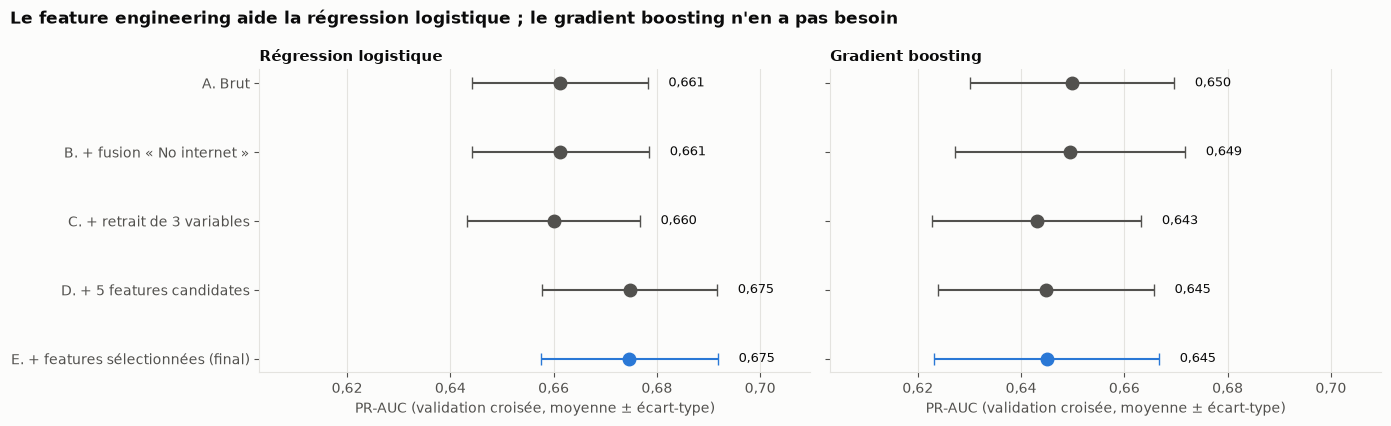

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3), sharey=True)
for ax, model_name in zip(axes, models):
    sub = ablation[ablation["modèle"] == model_name].iloc[::-1]
    is_final = sub["config"].str.startswith("E.")
    # Graphique en points (et non en barres) : l'axe ne démarre pas à 0, seule la position compte
    for i, (v, s, final) in enumerate(zip(sub["pr_auc"], sub["pr_auc_std"], is_final)):
        color = BLUE if final else TEXT_SECONDARY
        ax.errorbar(v, i, xerr=s, fmt="o", markersize=9, color=color, ecolor=color, elinewidth=1.5, capsize=4)
    ax.set_yticks(range(len(sub)), sub["config"])
    for i, (v, s) in enumerate(zip(sub["pr_auc"], sub["pr_auc_std"])):
        ax.text(v + s + 0.004, i, f"{v:.3f}".replace(".", ","), va="center", fontsize=9, color=TEXT)
    lo = ablation["pr_auc"].min() - 0.04
    ax.set_xlim(lo, ablation["pr_auc"].max() + 0.035)
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:.2f}".replace(".", ","))
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("PR-AUC (validation croisée, moyenne ± écart-type)")
    ax.set_title(model_name, fontsize=11)
fig.suptitle("Le feature engineering aide la régression logistique ; le gradient boosting n'en a pas besoin",
             x=0.01, ha="left", fontweight="bold", color=TEXT)
fig.tight_layout()
save_fig(fig, "04_ablation.png")
plt.show()

### 4.1 Contribution individuelle de chaque feature créée

À partir de la configuration D (5 candidates), on retire **une seule** feature créée et on mesure la variation de PR-AUC. Une variation négative signifie que la feature **aide** (la retirer dégrade le modèle).

In [11]:
baseline = ablation.set_index(["modèle", "config"])["pr_auc"]
rows = []
for m, factory in models.items():
    ref = baseline[(m, "D. + 5 features candidates")]
    for feat in CANDIDATE_FEATURES:
        others = tuple(f for f in CANDIDATE_FEATURES if f != feat)
        res = evaluate(factory, features=others, drop_cols=tuple(DROPPED_COLS))
        rows.append({"modèle": m, "feature retirée": feat, "delta_pr_auc": res["pr_auc"] - ref,
                     "std": res["pr_auc_std"]})
single = pd.DataFrame(rows)
single.pivot(index="feature retirée", columns="modèle", values="delta_pr_auc").round(4)

modèle,Gradient boosting,Régression logistique
feature retirée,,
fiber_month_to_month,-0.0026,0.0001
is_new_client,0.0000,0.0000
log_tenure,0.0000,-0.0100
nb_protections,-0.0004,0.0000
nb_streaming,-0.0002,0.0001


**Comment lire ces écarts :** l'écart-type de la PR-AUC entre plis est d'environ ±0,02. Un écart de quelques millièmes est donc **dans le bruit**. Ce qui compte, c'est la **tendance** et la **cohérence entre les deux modèles**.

### 4.2 Décision

**Règle de parcimonie :** une feature est gardée si la retirer dégrade **au moins un** des deux modèles d'au moins 0,001 de PR-AUC. Une feature inutile complexifie le pipeline et l'explication sans rien apporter.

| Feature | Verdict | Raison |
|---|---|---|
| `log_tenure` | ✅ Gardée | C'est elle qui porte le gain de la régression logistique (~+0,01). La vérification visuelle sur le logit suggérait l'inverse : **la mesure a tranché** |
| `fiber_month_to_month` | ✅ Gardée | Léger gain pour le gradient boosting ; traduit directement le segment prioritaire |
| `nb_protections`, `nb_streaming`, `is_new_client` | ❌ Abandonnées | Aucun apport : l'information est déjà portée par `tenure` et les colonnes de services |

**Autres constats :**
- La **fusion « No internet service »** est neutre en performance, mais supprime la multicolinéarité parfaite (coefficients interprétables).
- Le **retrait** de `gender`, `PhoneService`, `TotalCharges` coûte entre 0,001 et 0,007 de PR-AUC, **dans le bruit** (écart-type ≈ 0,02). On le maintient pour la simplicité (formulaire de l'app), l'éthique (genre) et la suppression d'une redondance.
- **Aperçu de la Phase 5** : sans réglage, la régression logistique fait **mieux** que le gradient boosting. Ce dataset est connu pour être assez « linéaire ». Les modèles complexes devront prouver qu'ils valent leur complexité.

## Conclusion de la Phase 4

- Le jeu de test est **sous clé** depuis la section 1 : toutes les décisions ont été prises en validation croisée sur l'entraînement.
- Le pipeline final `ChurnFeatureEngineer → OneHot + Scaler → modèle` produit une matrice numérique **sans valeur manquante ni colonne dupliquée**, avec des noms lisibles.
- Chaque choix de feature a été **validé par une étude d'ablation** sur deux familles de modèles, et non sur l'intuition seule.
- Le pipeline est prêt à recevoir n'importe quel modèle en Phase 5.